# 03 - Comparison of the two datasets
**AIN3101 Machine Learning Project** - Badr University in Assiut, Fall 2026

This notebook reads the results saved by `01_dry_bean.ipynb` and `02_raisin.ipynb`
(run those two first), draws the comparison figures and answers the comparison questions of the plan.

In [1]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from src.utils import *

## Results tables

In [2]:
bean = pd.read_csv(TABLE_DIR + "drybean_results.csv")
raisin = pd.read_csv(TABLE_DIR + "raisin_results.csv")

print("Dry Bean")
bean.round(4)

Dry Bean


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Best Params,Training Time (s),Tuning Time (s)
0,Logistic Regression,0.9192,0.9310,0.9295,0.9301,0.9193,C=100,0.489,2.5
1,Random Forest,0.9184,0.9315,0.9288,0.9300,0.9183,"max_depth=20, min_samples_split=10, n_estimato...",5.469,278.8
2,SVM,0.9236,0.9356,0.9340,0.9347,0.9236,"C=10, gamma=scale, kernel=rbf",0.439,24.6


In [3]:
print("Raisin")
raisin.round(4)

Raisin


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC,Best Params,Training Time (s),Tuning Time (s)
0,Logistic Regression,0.8778,0.8825,0.8778,0.8774,0.8774,0.9136,C=0.1,0.005,0.5
1,Random Forest,0.8667,0.8758,0.8667,0.8659,0.8659,0.9238,"max_depth=10, min_samples_split=5, n_estimator...",0.269,55.5
2,SVM,0.8722,0.8779,0.8722,0.8717,0.8717,0.9147,"C=0.1, kernel=linear",0.007,1.7


## Grouped bar charts (fig20 and fig21)
Same y-axis range for both datasets so the bars can be compared directly.

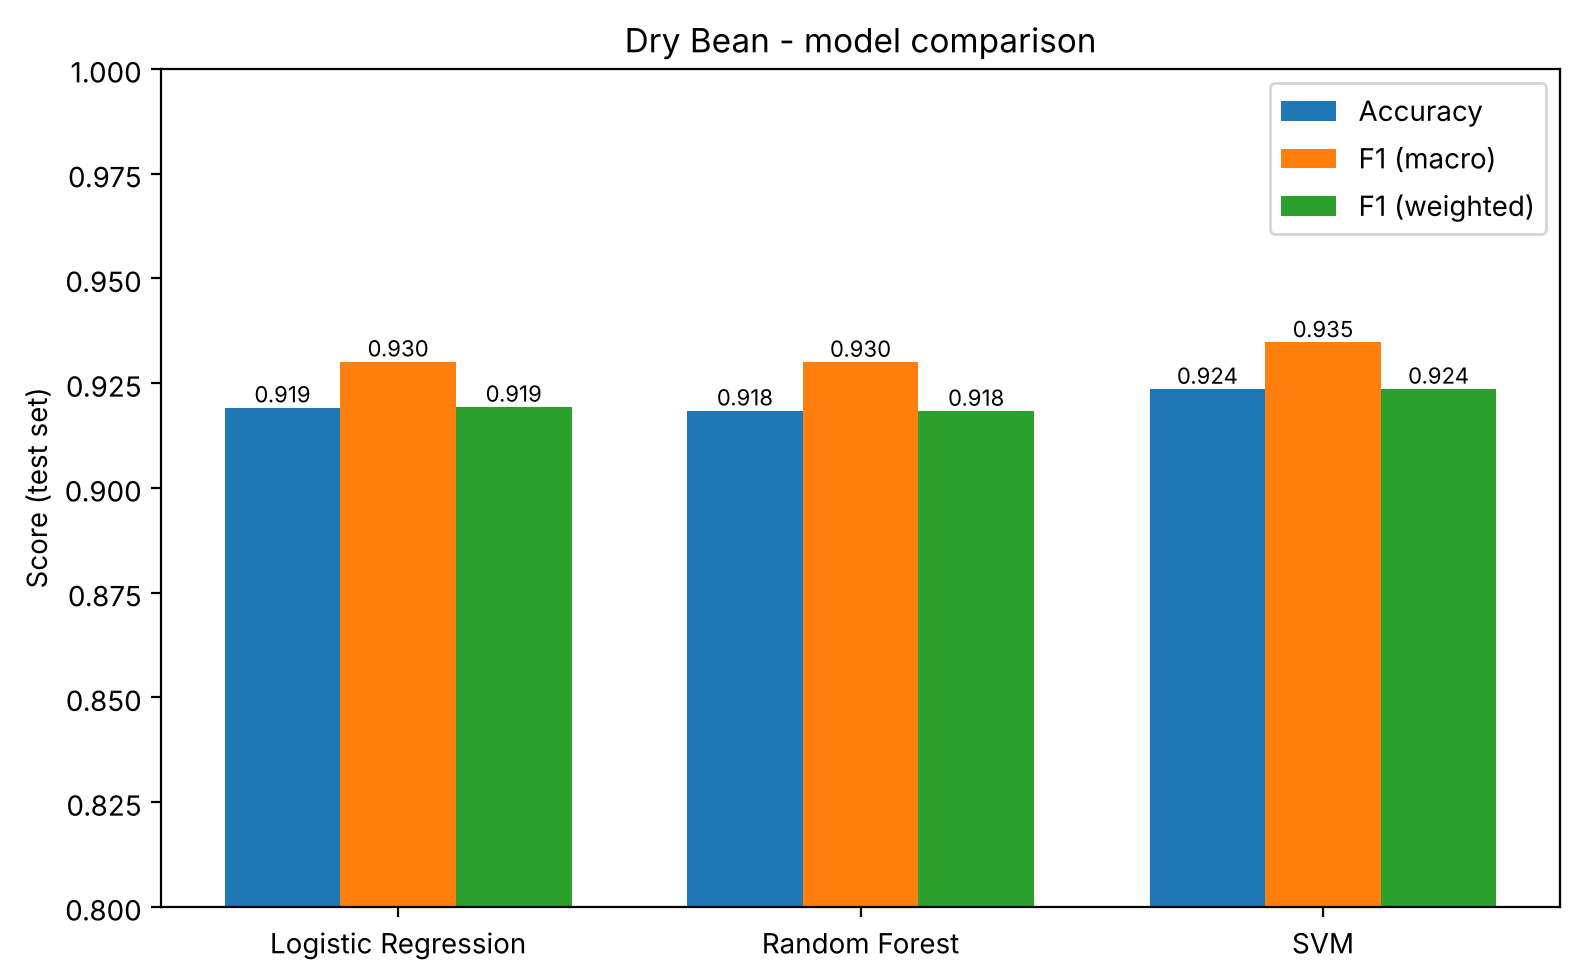

In [4]:
def plot_comparison(results, title, filename):
    metrics = ["Accuracy", "F1 (macro)", "F1 (weighted)"]
    x = np.arange(len(results))
    width = 0.25
    fig, ax = plt.subplots(figsize=(8, 5))
    for i, m in enumerate(metrics):
        bars = ax.bar(x + (i - 1) * width, results[m], width, label=m)
        ax.bar_label(bars, fmt="%.3f", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(results["Model"])
    ax.set_ylim(0.80, 1.00)          # same range for both datasets
    ax.set_ylabel("Score (test set)")
    ax.set_title(title)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(FIG_DIR + filename, dpi=150)
    plt.show()

plot_comparison(bean, "Dry Bean - model comparison", "fig20_drybean_comparison.png")

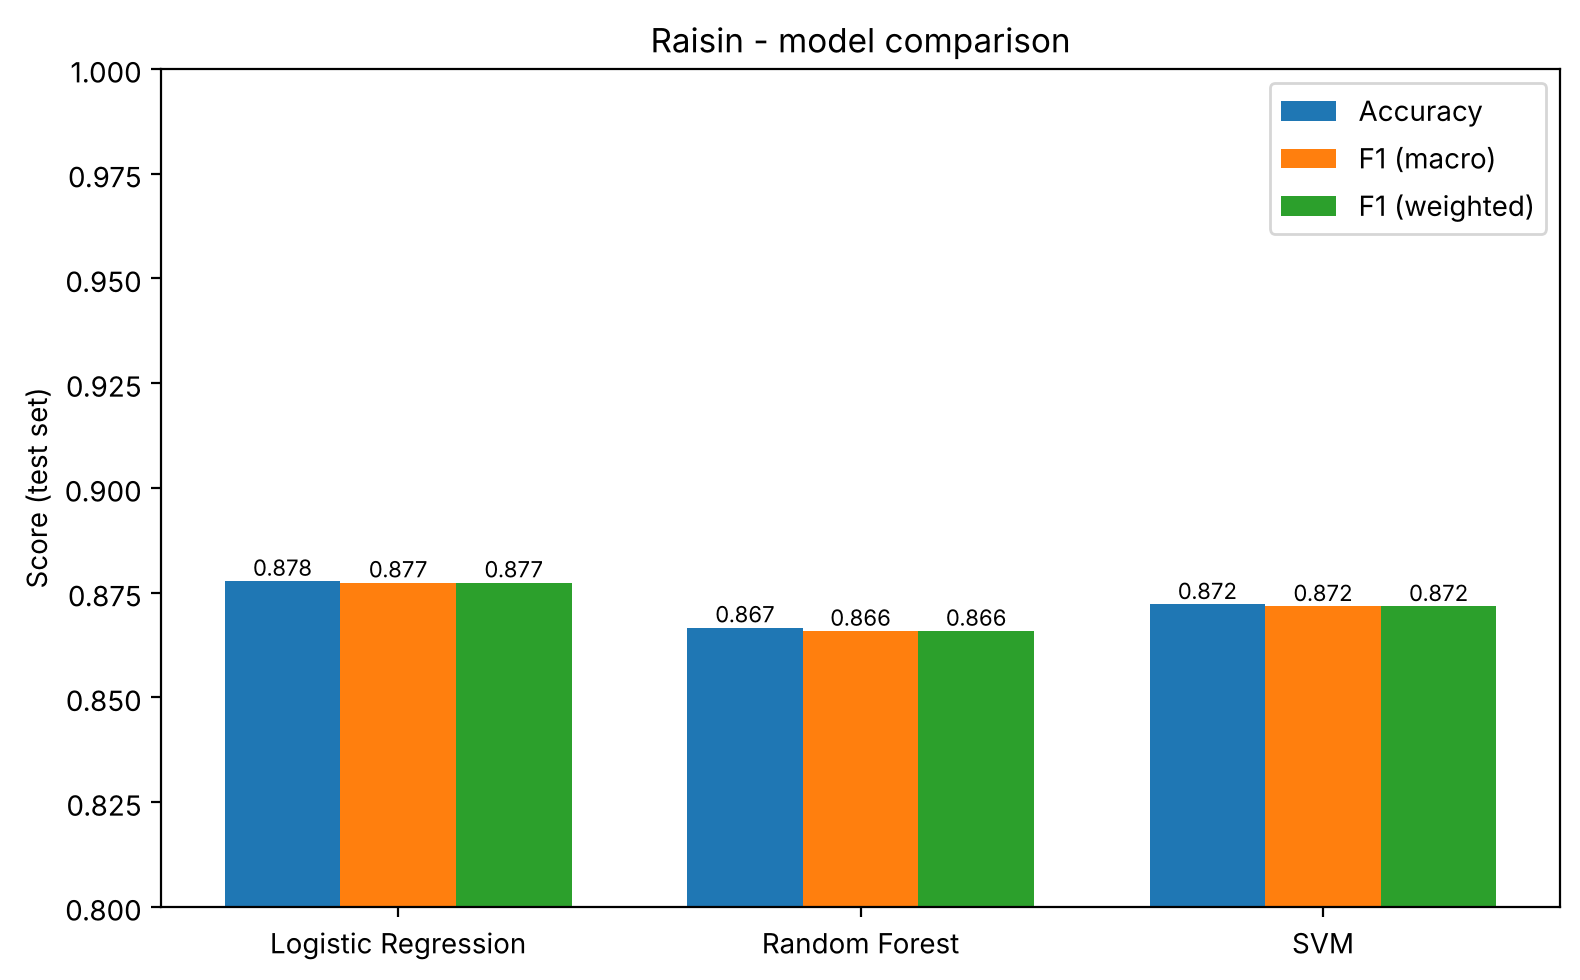

In [5]:
plot_comparison(raisin, "Raisin - model comparison", "fig21_raisin_comparison.png")

## Overfitting: train vs CV vs test

In [6]:
gap = pd.concat([pd.read_csv(TABLE_DIR + "drybean_overfitting.csv").assign(Dataset="Dry Bean"),
                 pd.read_csv(TABLE_DIR + "raisin_overfitting.csv").assign(Dataset="Raisin")])
gap = gap[["Dataset", "Model", "Train F1 (macro)", "CV F1 (macro)", "Test F1 (macro)", "Train - Test gap"]]
gap.to_csv(TABLE_DIR + "overfitting_both.csv", index=False)
gap.round(4)

,Dataset,Model,Train F1 (macro),CV F1 (macro),Test F1 (macro),Train - Test gap
0,Dry Bean,Logistic Regression,0.9402,0.9376,0.9301,0.0100
1,Dry Bean,Random Forest,0.9820,0.9361,0.9300,0.0520
2,Dry Bean,SVM,0.9509,0.9438,0.9347,0.0161
0,Raisin,Logistic Regression,0.8652,0.8665,0.8774,-0.0122
1,Raisin,Random Forest,0.9653,0.8614,0.8659,0.0994
2,Raisin,SVM,0.8680,0.8679,0.8717,-0.0038


## Stability check: does the result change with random_state?
We keep the best hyper-parameters found earlier and only change the `random_state` of the train/test split
(5 different splits). If the ranking of the models stays the same, our conclusion is stable.

In [7]:
def load_bean():
    df = pd.read_excel("../data/dry_bean/Dry_Bean_Dataset.xlsx").drop_duplicates()
    return df.drop(columns="Class"), LabelEncoder().fit_transform(df["Class"])

def load_raisin():
    df = pd.read_excel("../data/raisin/Raisin_Dataset.xlsx")
    return df.drop(columns="Class"), LabelEncoder().fit_transform(df["Class"])

datasets = {"Dry Bean": (load_bean(), "drybean_best_params.json"),
            "Raisin": (load_raisin(), "raisin_best_params.json")}

seeds = [0, 1, 2, 3, 4]
rows = []
for ds_name, ((X, y), param_file) in datasets.items():
    with open(TABLE_DIR + param_file) as f:
        best_params = json.load(f)
    for seed in seeds:
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
        for name, (pipe, grid) in get_models().items():
            pipe.set_params(**best_params[name])
            pipe.fit(X_tr, y_tr)
            f1 = f1_score(y_te, pipe.predict(X_te), average="macro")
            rows.append([ds_name, name, seed, f1])

stab = pd.DataFrame(rows, columns=["Dataset", "Model", "Seed", "Test F1 (macro)"])
summary = stab.groupby(["Dataset", "Model"])["Test F1 (macro)"].agg(["mean", "std", "min", "max"])
summary.to_csv(TABLE_DIR + "stability_check.csv")
summary.round(4)

mean     std     min     max
Dataset  Model                                              
Dry Bean Logistic Regression  0.9389  0.0071  0.9297  0.9460
         Random Forest        0.9393  0.0049  0.9327  0.9444
         SVM                  0.9452  0.0043  0.9407  0.9497
Raisin   Logistic Regression  0.8743  0.0225  0.8444  0.9055
         Random Forest        0.8642  0.0273  0.8165  0.8832
         SVM                  0.8709  0.0240  0.8331  0.8999

In [8]:
# which model wins on each split?
winners = stab.loc[stab.groupby(["Dataset", "Seed"])["Test F1 (macro)"].idxmax()]
winners.groupby("Dataset")["Model"].value_counts()

Dataset   Model              
Dry Bean  SVM                    5
Raisin    Logistic Regression    3
          Random Forest          1
          SVM                    1
Name: count, dtype: int64

## Answers to the comparison questions

**1. Which model won on each dataset?**
- Dry Bean: **SVM (rbf kernel, C=10, gamma=scale)** with accuracy 0.924 and macro F1 0.935 (fig20).
- Raisin: **Logistic Regression (C=0.1)** with accuracy 0.878 and macro F1 0.877 (fig21).

**2. Did the same model win on both? Why or why not?**
No. Dry Bean has 7 classes whose boundaries are curved (for example DERMASON, SIRA and SEKER are separated by a
combination of size and roundness), so the flexible rbf kernel of the SVM helps. Raisin has 2 classes that are
separated mainly by size, so a straight-line boundary is enough, and with only 720 training rows a simple,
strongly regularized model (LR with C=0.1, and SVM also chose a *linear* kernel) generalizes best.
On Raisin the three models are within one CV standard deviation of each other, so the "winner" there is not a
clear winner.

**3. Did dataset size (13,543 vs 900) and the number of classes affect the results?**
Yes, in two ways. (a) Scores: all models are about 6 points lower on Raisin, because its two classes overlap more
(fig12), not because binary is harder. (b) Stability: in the stability check the standard deviation of the test
F1 is about 0.005 on Dry Bean but about 0.02-0.03 on Raisin. With 180 test rows, a few grains change the result,
and the winner on Raisin changes between splits (LR 3 times, RF once, SVM once), while SVM wins all 5 splits on Dry Bean.

**4. Is there overfitting?**
Random Forest overfits the most on both datasets (train-test gap 0.05 on Dry Bean and 0.10 on Raisin): its deep
trees almost memorize the training data (low bias, high variance). It still generalizes reasonably because averaging
many trees reduces the variance. Logistic Regression and the linear SVM on Raisin show almost no gap (higher bias,
low variance). For every model the CV score was close to the test score, so the tuning was not over-optimistic.

**5. Trade-off between accuracy, speed and interpretability**
- Logistic Regression: fastest (fits in under a second, grid search in seconds), easiest to explain through
  coefficients, but the coefficients are misleading when features are highly correlated. Accuracy close to the best.
- SVM: best accuracy on Dry Bean, fast on these dataset sizes, but an rbf SVM is a black box (only permutation
  importance), and it gets slow on much larger datasets.
- Random Forest: needs no scaling and handles outliers well, gives built-in importances, but its grid search was by
  far the slowest (about 4.5 minutes on Dry Bean), it overfits the most, and it did not win on either dataset.

**6. Which classes were confused in Dry Bean, and why?**
DERMASON and SIRA (289 errors for the three models together), then BARBUNYA and CALI (80). These pairs have
overlapping size and shape features (fig03). BOMBAY is never confused because it is much larger than all the other
beans.

**Limitations**
- Only one test split per dataset; the stability check helps, but it reuses the hyper-parameters tuned on the
  `random_state=42` split.
- Raisin is small, so differences of 1% are not meaningful.
- The grids are limited (for example LR on Dry Bean chose C=100, the edge of the grid).
- We did not try class weights for the imbalanced Dry Bean data; macro F1 was already high for the small classes.
- The y-axis of fig20 and fig21 starts at 0.80 to make the differences visible, which also makes them look bigger than they are.